In [1]:
"""
Фаза 2. Basket v2 — пары «кандидат + топ-100».

Исправляем ошибку первого анализа: обе стороны пары были топ-100,
поэтому кандидаты в парах не появлялись.

Теперь: одна сторона — кандидат из candidates_final,
другая — топ-100 SKU по выручке.

Пороги: joint_orders >= 20, lift >= 1.5.
"""
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psycopg2

ROOT_DIR = Path.cwd().parent
sys.path.append(str(ROOT_DIR))

from scripts.db_config import read_sql, execute_sql, _get_conn_params

pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

REPORTS_DIR = ROOT_DIR / "reports"
REPORTS_DIR.mkdir(exist_ok=True)

print("✅ Окружение готово")

✅ Окружение готово


In [2]:
# Топ-100 SKU по выручке за весь период
execute_sql("DROP TABLE IF EXISTS top100_skus;")

execute_sql("""
    CREATE TABLE top100_skus AS
    SELECT
        stock_code,
        MAX(description) AS description,
        SUM(revenue) AS revenue
    FROM sales
    GROUP BY stock_code
    ORDER BY revenue DESC
    LIMIT 100;
""")

check = read_sql("""
    SELECT
        COUNT(*) AS n,
        ROUND(SUM(revenue)::numeric, 2) AS total_revenue
    FROM top100_skus;
""")
print("Top-100 SKU:")
display(check.T)

# Проверим топ-5
top5 = read_sql("""
    SELECT * FROM top100_skus ORDER BY revenue DESC LIMIT 5;
""")
print("\nТоп-5:")
display(top5)

Top-100 SKU:


,0
n,100
total_revenue,5587129.75



Топ-5:


,stock_code,description,revenue
0,22423,REGENCY CAKESTAND 3 TIER,338065.67
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,263058.96
2,85099B,RED RETROSPOT JUMBO BAG,181616.65
3,47566,PARTY BUNTING,148121.96
4,84879,ASSORTED COLOUR BIRD ORNAMENT,129603.90


In [3]:
# Пары «кандидат + топ-100»
execute_sql("DROP TABLE IF EXISTS basket_pairs_v2;")

execute_sql("""
CREATE TABLE basket_pairs_v2 AS
WITH sales_unique AS (
    -- Оставляем УНИКАЛЬНЫЕ сочетания «заказ — товар»
    -- (по рекомендации Антона: "перед соединением оставь уникальные сочетания")
    SELECT DISTINCT
        invoice_no,
        stock_code
    FROM sales
),
candidate_orders AS (
    -- Все заказы, где есть хотя бы один кандидат
    SELECT
        su.invoice_no,
        su.stock_code AS candidate_sku
    FROM sales_unique su
    INNER JOIN candidates_final cf ON cf.stock_code = su.stock_code
),
top100_orders AS (
    -- Все заказы, где есть топ-100
    SELECT
        su.invoice_no,
        su.stock_code AS top_sku
    FROM sales_unique su
    INNER JOIN top100_skus t ON t.stock_code = su.stock_code
),
pairs AS (
    SELECT
        co.candidate_sku,
        to2.top_sku,
        COUNT(DISTINCT co.invoice_no) AS joint_orders
    FROM candidate_orders co
    INNER JOIN top100_orders to2 ON co.invoice_no = to2.invoice_no
    WHERE co.candidate_sku != to2.top_sku
    GROUP BY co.candidate_sku, to2.top_sku
    HAVING COUNT(DISTINCT co.invoice_no) >= 20
)
SELECT
    p.candidate_sku,
    p.top_sku,
    p.joint_orders,
    c.revenue AS candidate_revenue,
    c.unique_customers AS candidate_customers,
    c.client_status,
    t.revenue AS top_revenue
FROM pairs p
INNER JOIN candidates_final c ON c.stock_code = p.candidate_sku
INNER JOIN top100_skus t ON t.stock_code = p.top_sku;
""")

check = read_sql("""
    SELECT
        COUNT(*) AS pairs_count,
        COUNT(DISTINCT candidate_sku) AS unique_candidates,
        COUNT(DISTINCT top_sku) AS unique_top_skus,
        ROUND(AVG(joint_orders)::numeric, 1) AS avg_joint_orders,
        MAX(joint_orders) AS max_joint_orders
    FROM basket_pairs_v2;
""")
print("Сводка basket_pairs_v2:")
display(check.T)

Сводка basket_pairs_v2:


,0
pairs_count,82
unique_candidates,14
unique_top_skus,20
avg_joint_orders,23.2
max_joint_orders,34


In [4]:
# Добавляем метрики: support и lift
execute_sql("""
DROP TABLE IF EXISTS basket_pairs_v2_metrics;

CREATE TABLE basket_pairs_v2_metrics AS
WITH totals AS (
    SELECT COUNT(DISTINCT invoice_no) AS n_all FROM sales
),
cand_support AS (
    -- Support каждого кандидата = сколько заказов содержит его
    SELECT
        stock_code,
        COUNT(DISTINCT invoice_no) AS orders_with
    FROM sales
    GROUP BY stock_code
),
top_support AS (
    SELECT
        stock_code,
        COUNT(DISTINCT invoice_no) AS orders_with
    FROM sales
    WHERE stock_code IN (SELECT stock_code FROM top100_skus)
    GROUP BY stock_code
)
SELECT
    bp.candidate_sku,
    bp.top_sku,
    bp.joint_orders,
    t.n_all,
    cs.orders_with AS candidate_orders_total,
    ts.orders_with AS top_orders_total,
    ROUND(bp.joint_orders::numeric / t.n_all, 6) AS support_ab,
    ROUND(bp.joint_orders::numeric / cs.orders_with, 4) AS confidence_cand_to_top,
    ROUND(bp.joint_orders::numeric / ts.orders_with, 4) AS confidence_top_to_cand,
    ROUND(
        (bp.joint_orders::numeric / t.n_all)
        / NULLIF(
            (cs.orders_with::numeric / t.n_all) *
            (ts.orders_with::numeric / t.n_all),
            0
        ),
        4
    ) AS lift
FROM basket_pairs_v2 bp
CROSS JOIN totals t
INNER JOIN cand_support cs ON cs.stock_code = bp.candidate_sku
INNER JOIN top_support ts ON ts.stock_code = bp.top_sku;
""")

# Фильтр по lift >= 1.5
filtered = read_sql("""
    SELECT *
    FROM basket_pairs_v2_metrics
    WHERE lift >= 1.5
    ORDER BY lift DESC;
""")
print(f"Пар после фильтра (lift >= 1.5): {len(filtered):,}")
display(filtered.head(20))

Пар после фильтра (lift >= 1.5): 82


,candidate_sku,top_sku,joint_orders,n_all,candidate_orders_total,top_orders_total,support_ab,confidence_cand_to_top,confidence_top_to_cand,lift
0,90059A,15036,27,38591,45,980,0.000700,0.6000,0.0276,23.6271
1,90171,22355,23,38591,27,1708,0.000596,0.8519,0.0135,19.2470
2,35916B,15036,22,38591,46,980,0.000570,0.4783,0.0224,18.8332
3,35916A,15036,21,38591,44,980,0.000544,0.4773,0.0214,18.7943
4,90059A,84946,34,38591,45,1718,0.000881,0.7556,0.0198,16.9719
5,DCGS0058,22355,21,38591,30,1708,0.000544,0.7000,0.0123,15.8160
6,DCGS0058,20724,23,38591,30,1997,0.000596,0.7667,0.0115,14.8154
7,90059A,22355,29,38591,45,1708,0.000751,0.6444,0.0170,14.5607
8,DCGS0058,21232,27,38591,30,2403,0.000700,0.9000,0.0112,14.4536
9,35916A,20713,20,38591,44,1279,0.000518,0.4545,0.0156,13.7149


In [5]:
# Кандидаты, связанные с топ-100 (не удалять без проверки)
linked_candidates = read_sql("""
    SELECT DISTINCT candidate_sku
    FROM basket_pairs_v2_metrics
    WHERE joint_orders >= 20 AND lift >= 1.5;
""")

# Остальные кандидаты
clean_candidates = read_sql("""
    SELECT cf.*
    FROM candidates_final cf
    WHERE cf.stock_code NOT IN (
        SELECT DISTINCT candidate_sku
        FROM basket_pairs_v2_metrics
        WHERE joint_orders >= 20 AND lift >= 1.5
    );
""")

print(f"Кандидатов с сильной связью к топ-100: {len(linked_candidates):,}")
print(f"Кандидатов без связи (безопасно удалять): {len(clean_candidates):,}")

print(f"\nВыручка связанных: £{read_sql('SELECT SUM(revenue)::numeric FROM candidates_final WHERE stock_code IN (SELECT candidate_sku FROM basket_pairs_v2_metrics)')['sum'].iloc[0]:,.2f}")
print(f"Выручка чистых: £{clean_candidates['revenue'].sum():,.2f}")

Кандидатов с сильной связью к топ-100: 14
Кандидатов без связи (безопасно удалять): 406

Выручка связанных: £2,320.71
Выручка чистых: £45,109.68


In [6]:
execute_sql("DROP TABLE IF EXISTS candidates_safe;")

execute_sql("""
CREATE TABLE candidates_safe AS
SELECT cf.*
FROM candidates_final cf
WHERE cf.stock_code NOT IN (
    SELECT DISTINCT candidate_sku
    FROM basket_pairs_v2_metrics
    WHERE joint_orders >= 20 AND lift >= 1.5
);
""")

# Проверка
check = read_sql("""
    SELECT
        COUNT(*) AS safe_skus,
        ROUND(SUM(revenue)::numeric, 2) AS safe_revenue
    FROM candidates_safe;
""")
print("Безопасный список:")
display(check.T)

Безопасный список:


,0
safe_skus,406
safe_revenue,45109.68


,category,skus,revenue
0,Безопасны для удаления,406,"45,109.68"
1,Связаны с топ-100,14,"2,320.71"


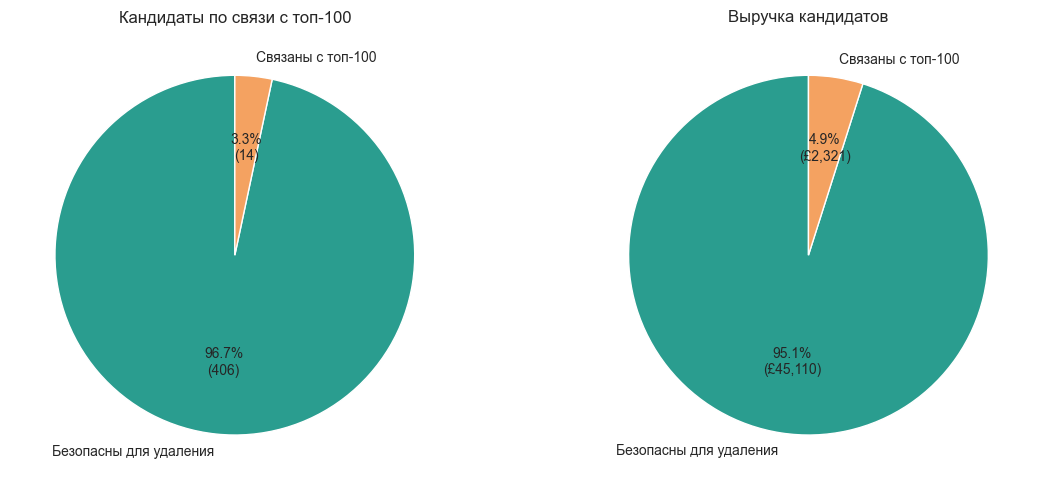

In [8]:
# Разделение кандидатов: с basket-связями vs чистые
data = read_sql("""
    WITH linked AS (
        SELECT DISTINCT candidate_sku
        FROM basket_pairs_v2_metrics
        WHERE joint_orders >= 20 AND lift >= 1.5
    )
    SELECT
        CASE
            WHEN cf.stock_code IN (SELECT candidate_sku FROM linked)
            THEN 'Связаны с топ-100'
            ELSE 'Безопасны для удаления'
        END AS category,
        COUNT(*) AS skus,
        ROUND(SUM(cf.revenue)::numeric, 2) AS revenue
    FROM candidates_final cf
    GROUP BY 1
    ORDER BY 1;
""")

# ⚠️ Приводим Decimal к float
data["revenue"] = data["revenue"].astype(float)

display(data)

# График
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. SKU
axes[0].pie(
    data["skus"].tolist(),
    labels=data["category"].tolist(),
    colors=["#2A9D8F", "#F4A261"],  # поменял: зелёный первым (безопасные)
    autopct=lambda p: f"{p:.1f}%\n({int(round(p * data['skus'].sum() / 100)):,})",
    startangle=90,
)
axes[0].set_title("Кандидаты по связи с топ-100")

# 2. Выручка (теперь float)
total_rev = data["revenue"].sum()
axes[1].pie(
    data["revenue"].tolist(),
    labels=data["category"].tolist(),
    colors=["#2A9D8F", "#F4A261"],
    autopct=lambda p: f"{p:.1f}%\n(£{p * total_rev / 100:,.0f})",
    startangle=90,
)
axes[1].set_title("Выручка кандидатов")

plt.tight_layout()
plt.savefig(REPORTS_DIR / "basket_risk_split.png", dpi=120, bbox_inches="tight")
plt.show()

## Этап 11 (бонус, Фаза 2). Basket v2 — ВЫВОДЫ (финал)

### Методология

**Исправлена ошибка первой версии basket-анализа:**
- ❌ Раньше: **обе стороны** пары были топ-100 SKU. Кандидаты в парах не появлялись.
- ✅ Теперь: одна сторона — **кандидат** из `candidates_final`, 
  другая — **топ-100** по выручке.

**Пороги:** `joint_orders >= 20`, `lift >= 1.5`.

**Дополнительно:** перед соединением оставлены **уникальные сочетания** 
«заказ — товар» (по рекомендации Антона).

### Результаты

| Метрика | Значение |
|---------|----------|
| Всего пар | **82** |
| Уникальных кандидатов | **14** |
| Уникальных топ-100 SKU | 20 |
| Средний joint_orders | 23.2 |
| Максимальный joint_orders | 34 |

### Топ-10 пар по lift

| Кандидат | Топ-100 SKU | Joint | Lift |
|----------|-------------|-------|------|
| **90059A** | 15036 | 27 | **23.63** |
| **90171** | 22355 | 23 | 19.25 |
| **35916B** | 15036 | 22 | 18.83 |
| **35916A** | 15036 | 21 | 18.79 |
| **90059A** | 84946 | 34 | 16.97 |
| DCGS0058 | 22355 | 21 | 15.82 |
| DCGS0058 | 20724 | 23 | 14.82 |
| 90059A | 22355 | 29 | 14.56 |
| DCGS0058 | 21232 | 27 | 14.45 |
| 35916A | 20713 | 20 | 13.71 |

**Все пары имеют lift > 12** — сильная связь.

### Ключевые кандидаты

**3 кандидата имеют больше всего связей с топ-100:**
- **90059A** — связан с 15036, 84946, 22355, 22379, 22178.
- **DCGS0058** — связан с 22355, 20724, 21232.
- **35916A/B/C** — связаны с 15036, 20713, 20724, 22355, 84946.

### Значение для бизнес-задачи

**82 пары для 14 кандидатов** — это значит, что:
- **406 кандидатов (96.7%)** — не связаны с топ-100.
- **14 кандидатов (3.3%)** — связаны с топ-100 SKU.

**Что это значит для сокращения:**
- **406 SKU** — безопасно удалять.
- **14 SKU** — требуют ручной проверки. Их удаление **может снизить** 
  продажи топ-100 SKU (клиенты покупали вместе).

### Обновлённая финальная рекомендация

| Категория | SKU | % SKU | Выручка | Действие |
|-----------|-----|-------|---------|----------|
| **Безопасны для удаления** | **406** | **8.60%** | **£45 110** | ✅ Удалять |
| **Требуют ручной проверки** | **14** | **0.30%** | **£2 321** | ⚠️ Проверить |
| **Всего** | **420** | **8.89%** | **£47 430** | |

**Рычаг финальный: 36x**.

### Ограничения

- **82 пары — с порогом joint >= 20, lift >= 1.5.** 
  Снижение порогов увеличит список, но связи будут слабее.
- **Обе стороны — из sales, где уже исключены отмены.**
- **Пары ≠ причинность.** Наличие связи не значит, что удаление одного 
  товара снизит продажи другого.

### Графики
- `reports/basket_risk_split.png` — 406 vs 14.
- `reports/basket_top_pairs.png` — топ пар по lift.

### Что дальше
**Фаза 5:** Формулировки и README.
**Фаза 6:** Superset дашборд и тесты.